# Customer EDA: Initial Dataset Inspection

> This CSV was reconstructed from pasted text fragments and has not been verified as the complete original dataset.
> The goal here is only to inspect the available data before any cleaning or modeling.

In [1]:
from pathlib import Path

import pandas as pd

data_path = Path("../data/ecommerce_customers_reconstructed.csv")
if not data_path.exists():
    data_path = Path("data/ecommerce_customers_reconstructed.csv")

df = pd.read_csv(data_path)
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel Wrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common Diazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582 Cobbborough, DC...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway Port Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage Port Jacobville, PR 37...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


### Preview rows

In [2]:
print("First 5 rows:")
display(df.head())
print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel Wrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common Diazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582 Cobbborough, DC...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway Port Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage Port Jacobville, PR 37...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092



Last 5 rows:


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
460,jimmy11@hardin.com,"496 Bush Turnpike Apt. 674 Donnabury, OR 3259...",DarkGoldenRod,32.975182,13.909916,37.792238,4.297687,630.422763
461,patriciajackson@jenkins.info,"981 Matthew Valley Apt. 621 Lake Tracyburgh, ...",Thistle,32.004753,11.395209,37.332814,3.803365,463.745981
462,rayvanessa@fischer.com,"2583 Mark Springs Lake Robert, AL 40928",White,34.197060,13.033566,37.076795,2.633420,493.180216
463,gharrison@davis.com,04140 Cameron Brooks Apt. 724 South Laurenber...,MediumSpringGreen,33.177205,11.622777,35.968896,3.634094,501.209173
464,lisa94@jackson.com,40288 Stephens Corner Apt. 221 West Stephanie...,CadetBlue,32.727319,13.013376,36.651278,2.367848,458.376911


### Dataset shape

In [3]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.shape

Rows: 465
Columns: 8


(465, 8)

### Column names and dtypes

In [4]:
df.dtypes

Email                       str
Address                     str
Avatar                      str
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object

### Numerical summary

In [5]:
df.describe(include="number")

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,465.000000,465.000000,465.000000,465.000000,465.000000
mean,33.028057,12.048539,37.075346,3.555429,499.769123
std,0.977854,1.011706,1.013388,0.993453,80.160790
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.335990,11.371767,36.360247,2.964498,445.062186
50%,33.029332,11.982045,37.087926,3.549036,501.100245
75%,33.700400,12.795189,37.722367,4.130563,549.860590
max,36.139662,15.126994,40.005182,6.922689,765.518462


### Missing values and duplicates

In [6]:
missing_values = df.isna().sum()
duplicate_rows = df.duplicated().sum()

print("Missing values by column:")
display(missing_values)
print(f"\nDuplicate rows: {duplicate_rows}")

Missing values by column:


Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


Duplicate rows: 0


### Duplicate customer emails

In [7]:
email_column = "Email" if "Email" in df.columns else "email"
email_duplicates = df[df[email_column].duplicated(keep=False)]

print(f"Distinct email addresses: {df[email_column].nunique()}")
print(f"Duplicate email rows: {df[email_column].duplicated().sum()}")
print(f"Duplicate email values: {email_duplicates[email_column].nunique()}")
display(email_duplicates[[email_column]].head())

Distinct email addresses: 465
Duplicate email rows: 0
Duplicate email values: 0


,Email


### Concise dataset summary

In [8]:
summary = {
    "row_count": int(df.shape[0]),
    "column_count": int(df.shape[1]),
    "distinct_emails": int(df["Email"].nunique()),
    "missing_values_total": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_email_rows": int(df["Email"].duplicated().sum()),
    "columns": list(df.columns),
}

summary

{'row_count': 465,
 'column_count': 8,
 'distinct_emails': 465,
 'missing_values_total': 0,
 'duplicate_rows': 0,
 'duplicate_email_rows': 0,
 'columns': ['Email',
  'Address',
  'Avatar',
  'Avg. Session Length',
  'Time on App',
  'Time on Website',
  'Length of Membership',
  'Yearly Amount Spent']}

## Data Cleaning

This section creates a separate DataFrame named `df_clean` from the original data. We will not change the original CSV file. We will only check for problems and document what is justified by the records we have.

In [9]:
df_clean = df.copy()

rows_before_cleaning = len(df_clean)
print("Rows before cleaning:", rows_before_cleaning)

missing_before = df_clean.isnull().sum()
print("\nMissing values before cleaning:")
display(missing_before)

duplicate_rows_before = df_clean.duplicated().sum()
print("\nExact duplicate rows before cleaning:", duplicate_rows_before)

if duplicate_rows_before > 0:
    df_clean = df_clean.drop_duplicates()
    print("Duplicate rows removed:", duplicate_rows_before)
else:
    print("No exact duplicate rows found. No row removal was needed.")

email_col = "Email"
email_duplicates = df_clean[df_clean[email_col].duplicated(keep=False)]
print("\nDuplicate customer email rows:", df_clean[email_col].duplicated().sum())
print("Duplicate customer email values:")
display(email_duplicates[[email_col]].drop_duplicates())

print("\nData types before cleaning:")
display(df_clean.dtypes)

numeric_columns = df_clean.select_dtypes(include=["number"]).columns
print("\nNumerical columns:")
display(numeric_columns)
print("\nNumerical summary:")
display(df_clean[numeric_columns].describe())

rows_after_cleaning = len(df_clean)
missing_after = df_clean.isnull().sum()
duplicate_rows_after = df_clean.duplicated().sum()

print("\nRows after cleaning:", rows_after_cleaning)
print("Missing values remaining:")
display(missing_after)
print("Duplicate rows remaining:", duplicate_rows_after)
print("\nData types after cleaning:")
display(df_clean.dtypes)

Rows before cleaning: 465

Missing values before cleaning:


Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


Exact duplicate rows before cleaning: 0
No exact duplicate rows found. No row removal was needed.

Duplicate customer email rows: 0
Duplicate customer email values:


,Email



Data types before cleaning:


...

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,465.000000,465.000000,465.000000,465.000000,465.000000
mean,33.028057,12.048539,37.075346,3.555429,499.769123
std,0.977854,1.011706,1.013388,0.993453,80.160790
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.335990,11.371767,36.360247,2.964498,445.062186
50%,33.029332,11.982045,37.087926,3.549036,501.100245
75%,33.700400,12.795189,37.722367,4.130563,549.860590
max,36.139662,15.126994,40.005182,6.922689,765.518462



Rows after cleaning: 465
Missing values remaining:


Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate rows remaining: 0

Data types after cleaning:


Email                       str
Address                     str
Avatar                      str
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object

### Cleaning decisions

- We created `df_clean` from the original DataFrame so the CSV file stays unchanged.
- Missing values were checked with `isnull().sum()`. There were no missing values in the reconstructed data, so no rows were dropped or filled.
- Exact duplicate rows were checked with `duplicated().sum()` and `drop_duplicates()`. No exact duplicates were found.
- Duplicate customer emails were checked before making any decision. No duplicate email values were found, so no customer records were removed.
- Column types were checked with `dtypes`. The numerical columns already look valid, and the summary statistics show sensible values.
- No invalid numeric values were identified from the data we have, so we did not guess or replace values.

## Exploratory Data Analysis (EDA)

We will use the cleaned DataFrame `df_clean` to look at the distribution of key variables and their relationship with yearly spending.


### Distribution of Yearly Amount Spent

This histogram shows how the yearly spending values are spread across the dataset.


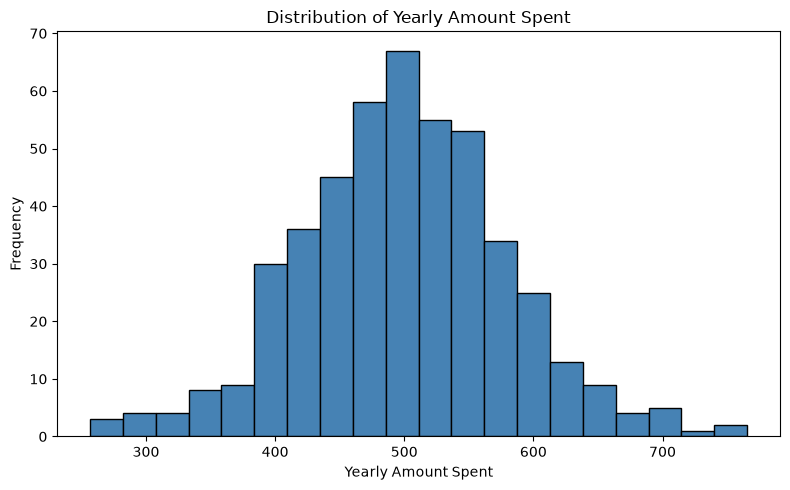

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_clean["Yearly Amount Spent"], bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Yearly Amount Spent")
plt.xlabel("Yearly Amount Spent")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


The histogram shows the spread of yearly spending values across the dataset. The distribution is centered around a moderate range, and the values appear to vary across the sample.


### Length of Membership vs Yearly Amount Spent

This scatter plot helps us compare membership length with customer spending.


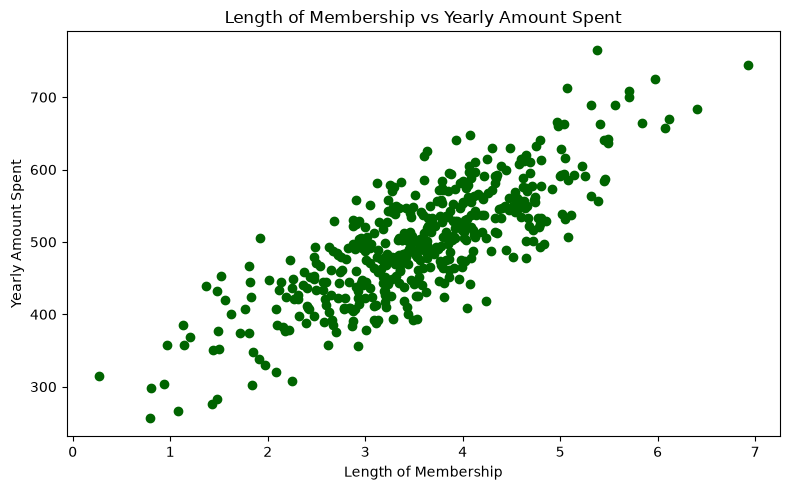

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Length of Membership"], df_clean["Yearly Amount Spent"], color="darkgreen")
plt.title("Length of Membership vs Yearly Amount Spent")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.tight_layout()
plt.show()


The scatter plot shows how membership length and spending relate across the records. The pattern appears to spread upward as membership length increases, but the relationship should be read from the actual points rather than assumed.


### Time on App vs Yearly Amount Spent

This scatter plot compares time spent in the app with total yearly spending.


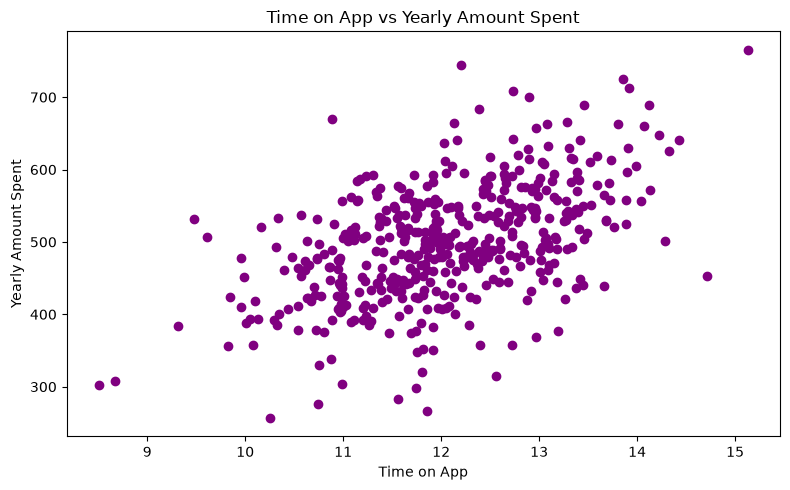

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Time on App"], df_clean["Yearly Amount Spent"], color="purple")
plt.title("Time on App vs Yearly Amount Spent")
plt.xlabel("Time on App")
plt.ylabel("Yearly Amount Spent")
plt.tight_layout()
plt.show()


The scatter plot shows the spread of app usage against yearly spending. It helps us see whether higher app time is associated with higher spending in this dataset.


### Correlation Heatmap

This heatmap shows how strongly the numerical columns relate to each other.


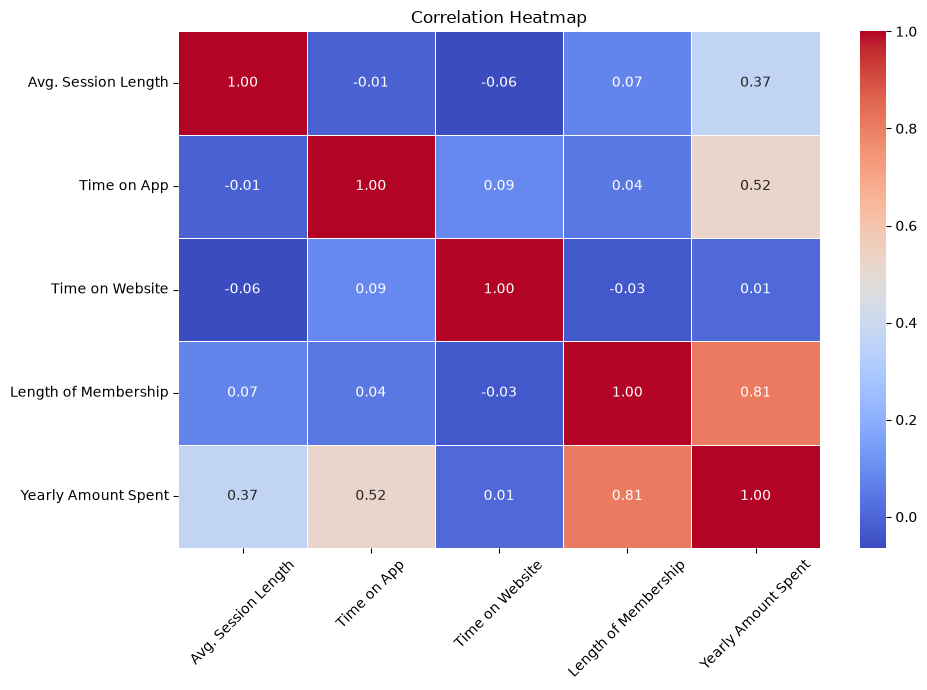

In [13]:
import seaborn as sns

numeric_df = df_clean.select_dtypes(include=["number"])
correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


The heatmap shows the pairwise correlations among the numerical variables. The strongest values are the ones closest to 1 or -1, while values near 0 indicate weaker relationships.


## Simple Linear Regression

`Length of Membership` is the input feature, or X. `Yearly Amount Spent` is the target variable, or y.


In [14]:
X = df_clean[["Length of Membership"]]
y = df_clean["Yearly Amount Spent"]

print(X.head())
print(y.head())


   Length of Membership
0              4.082621
1              2.664034
2              4.104543
3              3.120179
4              4.446308
0    587.951054
1    392.204933
2    487.547505
3    581.852344
4    599.406092
Name: Yearly Amount Spent, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 372
Testing rows: 93


In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained")


Model trained


In [17]:
y_pred = model.predict(X_test)

print(y_pred[:5])


[488.14957793 470.75025004 451.49293834 611.71840192 627.50326087]


In [18]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R^2:", round(r2, 4))


MAE: 39.4
R^2: 0.6979


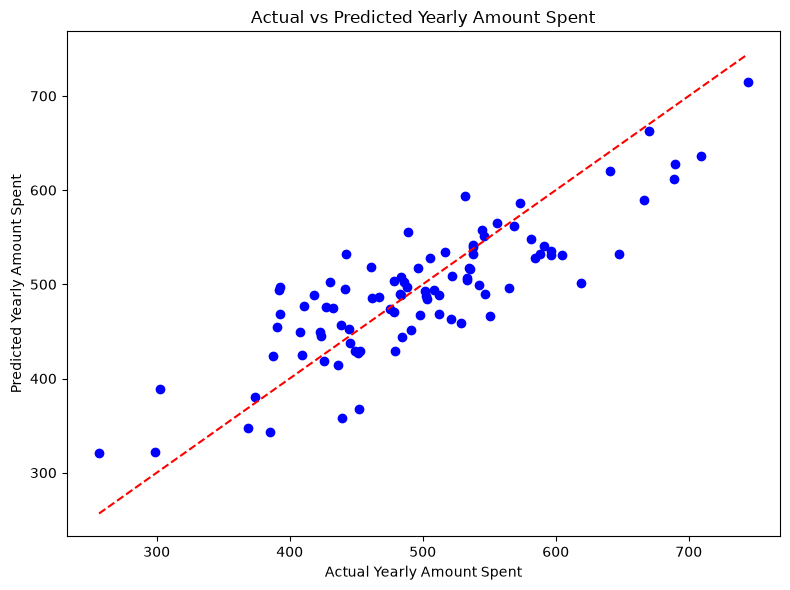

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--")
plt.title("Actual vs Predicted Yearly Amount Spent")
plt.xlabel("Actual Yearly Amount Spent")
plt.ylabel("Predicted Yearly Amount Spent")
plt.tight_layout()
plt.show()


The linear regression model using only `Length of Membership` achieved a MAE of 39.40 and an R² of 0.6979 on the test set. This means the model explains about 69.8% of the variation in `Yearly Amount Spent` for these test observations, but it does not prove causation and there is still prediction error.
